In [6]:
import sys, os

project_root = os.path.abspath('..')        
if project_root not in sys.path:
    sys.path.insert(0, project_root)        
    
from src.pde import HeatEquation1D, HeatPDEConditions
from src.networks import PINN
from src.generate import generate_data
from utils.training import train

from utils.evaluate import test_pinn_solution

import torch.nn as nn
import torch.optim as optim



PDE_BATCH_SIZE = 4096
IC_BATCH_SIZE = 4096
BC_BATCH_SIZE = 4096

BOUNDARIES = {
    'x_min' : -1,
    'x_max': 1,
    't_min': 0,
    't_max': 1
}

PDE = HeatEquation1D(D=0.5)
Conditions = HeatPDEConditions(cost_function=nn.MSELoss())
epochs = 5000

model = PINN(
    N_IN=2,
    N_HID=16,
    N_OUT=1,
    activation=nn.Tanh)


adam = optim.Adam(model.parameters(),lr=5e-4)


train_params = {
    'epochs' : epochs,
    'pde_batch_size' : PDE_BATCH_SIZE,
    'ic_batch_size' : IC_BATCH_SIZE,
    'bc_batch_size' : BC_BATCH_SIZE,
    'boundaries': BOUNDARIES,
    'optim' : adam,
    'model' : model,
    'PDE' : PDE,
    'Conditions' : Conditions,
    'l_ic' : 0.5,
    'l_bc' : 0.5,
    'epochs' : epochs,
    
}

model, history, exact_hist = train(train_params)



################################ Epoch: 0 ################################
loss: 0.5428251028060913
################################ Epoch: 10 ################################
loss: 0.4041082262992859
################################ Epoch: 20 ################################
loss: 0.3109419345855713
################################ Epoch: 30 ################################
loss: 0.24719461798667908
################################ Epoch: 40 ################################
loss: 0.2215510457754135
################################ Epoch: 50 ################################
loss: 0.20916247367858887
################################ Epoch: 60 ################################
loss: 0.21162636578083038
################################ Epoch: 70 ################################
loss: 0.20164670050144196
################################ Epoch: 80 ################################
loss: 0.2060508131980896
################################ Epoch: 90 ################################
loss: 0.2047

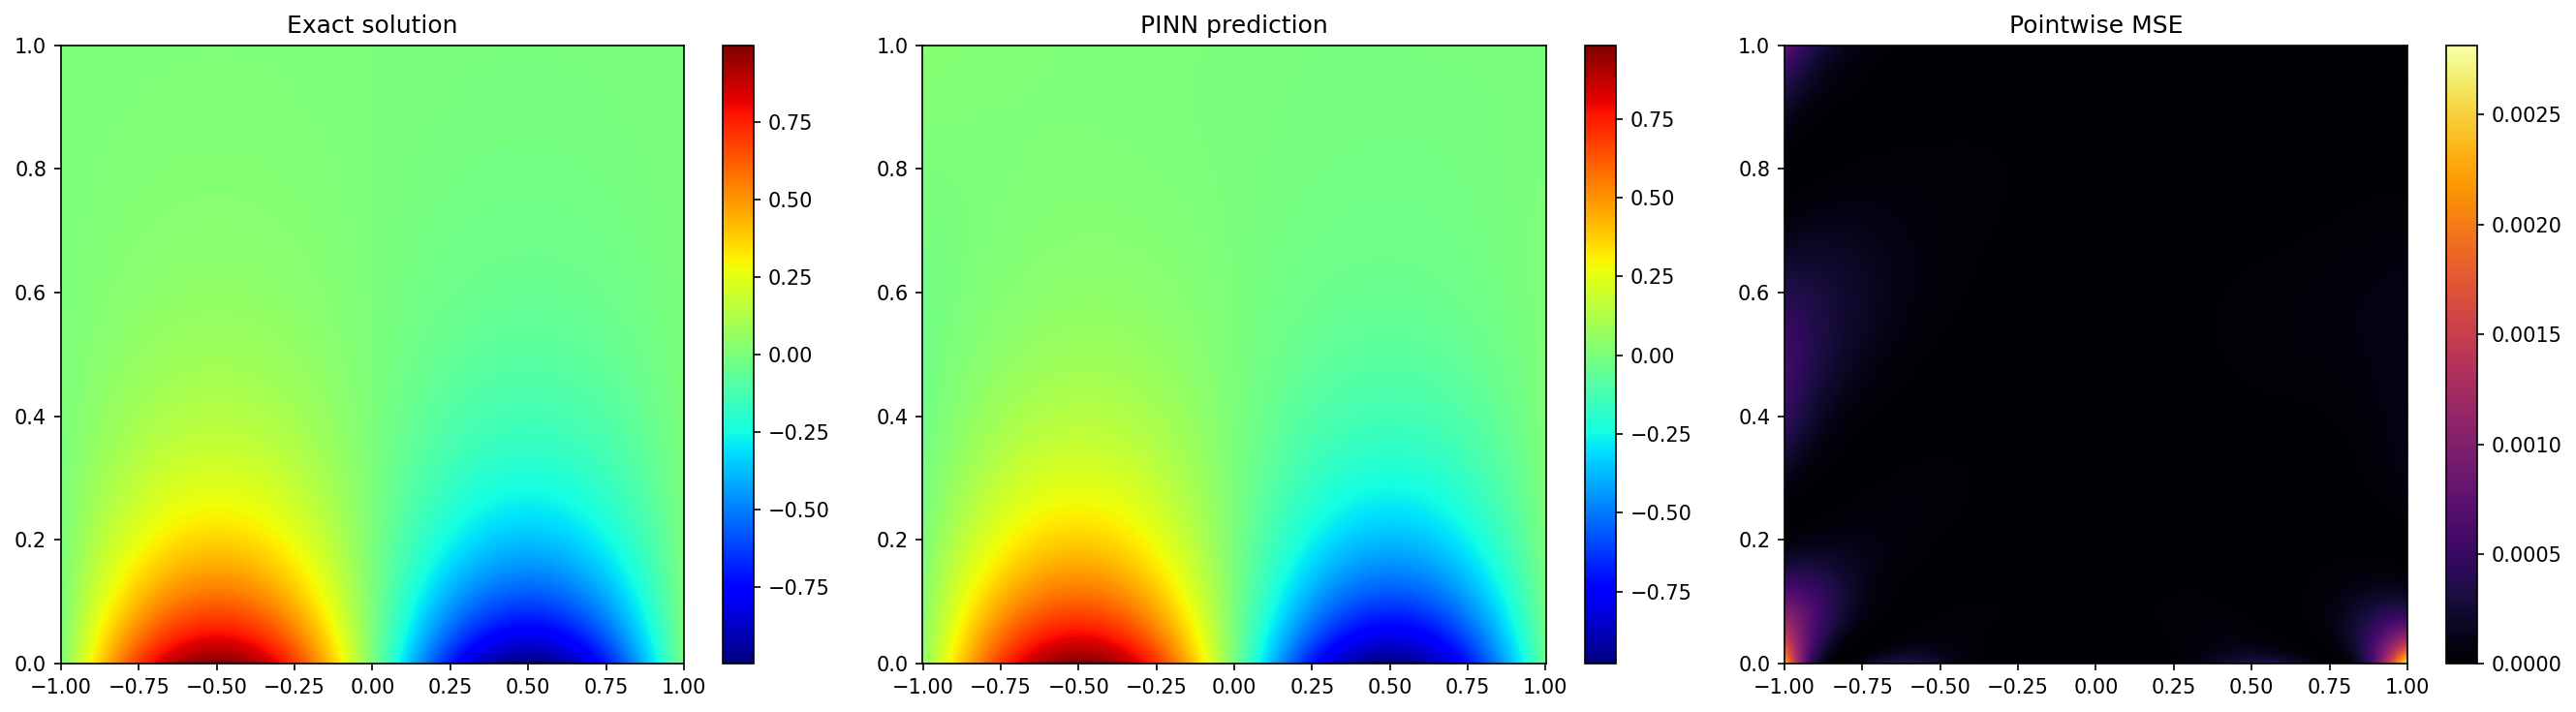

In [7]:
import matplotlib.pyplot as plt

Xg, Tg, exact, pred, mse = test_pinn_solution(model, boundaries= BOUNDARIES, D=PDE.D, N_test=1024)

plt.figure(figsize=(18,5), dpi=150)

# ---- Exact ----
plt.subplot(1,3,1)
plt.title("Exact solution")
plt.pcolormesh(Xg, Tg,  exact, shading='auto', cmap='jet')
plt.colorbar()

# ---- Predicted ----
plt.subplot(1,3,2)
plt.title("PINN prediction")
plt.pcolormesh(Xg,Tg, pred, shading='auto', cmap='jet')
plt.colorbar()

# ---- MSE ----
plt.subplot(1,3,3)
plt.title("Pointwise MSE")
plt.pcolormesh( Xg,Tg, mse, shading='auto', cmap='inferno')
plt.colorbar()

plt.tight_layout()
plt.show()
